# **Previsão de Churn (Abandono) em Telecom (KAN)**

# 1. Inicialização e importação de bibliotecas

In [ ]:
import sys

def in_colab():
    return 'google.colab' in sys.modules

In [ ]:
if in_colab():
    !pip install optuna
    !pip install pykan

In [ ]:
# Sistema e utilitários
import random
from copy import deepcopy
import warnings

# Bibliotecas principais
import pandas as pd
import numpy as np
import optuna

# Matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Wedge, Circle, Rectangle

# Scikit-learn
from sklearn.metrics import log_loss, classification_report, mean_squared_error
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import precision_recall_curve
from sklearn.exceptions import ConvergenceWarning
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.utils import shuffle


# Outros
import torch
import torch.nn as nn
import tensorflow as tf


# KAN
from kan import KAN

In [ ]:
# Remove warnings:
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# 2. Importando banco de dados


In [ ]:
# Importar banco de dados
if in_colab():
    data = pd.read_csv("customer_churn_telecom_services.csv")
else:
    data = pd.read_csv("../customer_churn_telecom_services.csv")
data.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# 3. Dividindo dados

In [ ]:
def separa_classe(df_class):
    df_class = shuffle(df_class, random_state=42)

    n = len(df_class)
    train = df_class.iloc[:int(0.5*n)]
    val   = df_class.iloc[int(0.5*n):int(0.75*n)]
    test  = df_class.iloc[int(0.75*n):]

    return train, val, test


def balanceamento(df_maior, df_menor):
    df_menor_bal = df_menor.sample(n=len(df_maior), replace=True, random_state=42)
    return df_menor_bal


def junta_e_mistura(df_x, df_y):
  return shuffle(pd.concat([df_x, df_y]), random_state=42)

In [ ]:
# Separar classes
# Classe 0 = Churn no
# Classe 1 = Churn yes
data_cl0 = data[data["Churn"] == "No"]
data_cl1 = data[data["Churn"] == "Yes"]

# Para cada classe, separar treino(50%), validação(25%) e teste(25%) de cada classe
data_cl0_train, data_cl0_val, data_cl0_test = separa_classe(data_cl0)
data_cl1_train, data_cl1_val, data_cl1_test = separa_classe(data_cl1)

# Balancear os dados de treino e validação da classe 2 até ter mesma quantidade que os da classe 1
data_cl1_train = balanceamento(data_cl0_train, data_cl1_train)
data_cl1_val = balanceamento(data_cl0_val, data_cl1_val)


# Embaralhar dados de treino, validação e teste
data_train = junta_e_mistura(data_cl0_train, data_cl1_train)
data_val = junta_e_mistura(data_cl0_val, data_cl1_val)
data_test = junta_e_mistura(data_cl0_test, data_cl1_test)

In [ ]:
print("Tamanhos finais:")
print("Treino:", data_train.shape)
print("Validação:", data_val.shape)
print("Teste:", data_test.shape)

Tamanhos finais:
Treino: (5174, 20)
Validação: (2586, 20)
Teste: (1762, 20)


# 4. Tratamento de dados

In [ ]:
# ===============================
# Funções de pré-processamento
# ===============================
def treat_missing(df):
    df = df.copy()

    # Strings vazias ou só espaços → NaN
    df = df.replace(r"^\s*$", np.nan, regex=True)

    print("Linhas removidas:", df.isna().any(axis=1).sum())

    # Remove linhas com qualquer NaN
    df = df.dropna().reset_index(drop=True)

    return df


def fix_inconsistencies(df):
    df = df.copy()

    # 1. TotalCharges (string -> numeric)
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

    return df


def treating_data(df):
    df = df.copy()

    # ===============================
    # 1. Binárias Yes / No (TODAS)
    # ===============================
    yes_no_cols = [
        "Partner", "Dependents", "PhoneService",
        "PaperlessBilling", "MultipleLines",
        "OnlineSecurity", "OnlineBackup",
        "DeviceProtection", "TechSupport",
        "StreamingTV", "StreamingMovies"
    ]
    for col in yes_no_cols:
        if col in df.columns:
            df[col] = (df[col] == "Yes").astype(int)

    # ===============================
    # 2. Gender
    # ===============================
    df["gender"] = (df["gender"] == "Male").astype(int)

    # ===============================
    # 3. One-Hot Encoding
    # ===============================
    cat_cols = [
        "InternetService",
        "Contract",
        "PaymentMethod"
    ]
    df = pd.get_dummies(
        df,
        columns=cat_cols,
        drop_first=False,
        dtype=int
    )

    # ===============================
    # 4. Agregação de serviços (remove ruído)
    # ===============================
    service_cols = [
        "OnlineSecurity", "OnlineBackup",
        "DeviceProtection", "TechSupport",
        "StreamingTV", "StreamingMovies"
    ]

    df["num_services"] = df[service_cols].sum(axis=1)
    df.drop(columns=service_cols, inplace=True)

    return df


def new_features(df):
    # Média de cobrança mensal
    df["AvgMonthlyCharge"] = df["TotalCharges"] / (df["tenure"] + 1)

    # Cliente novo
    df["is_new_customer"] = (df["tenure"] <= 6).astype(int)

    return df

In [ ]:
# 0. Copia banco de dados
tratando_train = data_train.copy()
tratando_val = data_val.copy()
tratando_test = data_test.copy()

In [ ]:
#1. Trata dados faltando:
tratando_train = treat_missing(tratando_train)
tratando_val = treat_missing(tratando_val)
tratando_test = treat_missing(tratando_test)

Linhas removidas: 6
Linhas removidas: 2
Linhas removidas: 3


In [ ]:
# 2. Muda target de "Yes"/"No" para 1/0:
tratando_train["Churn"] = (tratando_train["Churn"] == "Yes").astype(int)
tratando_val["Churn"] = (tratando_val["Churn"] == "Yes").astype(int)
tratando_test["Churn"] = (tratando_test["Churn"] == "Yes").astype(int)

In [ ]:
# 3. Fix Inconsistências
tratando_train = fix_inconsistencies(tratando_train)
tratando_val = fix_inconsistencies(tratando_val)
tratando_test = fix_inconsistencies(tratando_test)

In [ ]:
# 4. Tratando dados:
tratando_train = treating_data(tratando_train)
tratando_val = treating_data(tratando_val)
tratando_test = treating_data(tratando_test)

In [ ]:
# 5. Add novas features:
tratando_train = new_features(tratando_train)
tratando_val = new_features(tratando_val)
tratando_test = new_features(tratando_test)

In [ ]:
# 6. Separa valores target do resto do datasets:
target = "Churn"

# - Separa valores target de treino, validação e teste:
y_train = tratando_train[target]
y_val   = tratando_val[target]
y_test  = tratando_test[target]

# - Remover os valores target dos datasets para passar ao preprocessor:
tratando_train = tratando_train.drop(columns=[target])
tratando_val = tratando_val.drop(columns=[target])
tratando_test = tratando_test.drop(columns=[target])

In [ ]:
# 7. Normalização
# Separa colunas entree categoricas e numericas:
cat_cols = ["InternetService", "Contract", "PaymentMethod"]
one_hot_cols = [c for c in tratando_train.columns if any(x in c for x in cat_cols)]
num_cols = [c for c in tratando_train.columns if c not in one_hot_cols + [target]]

# Cria preprocessor:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", "passthrough", one_hot_cols)
    ]
)

# Fit no treino:
preprocessor.fit(tratando_train)

# Transform no resto:
x_train = preprocessor.transform(tratando_train)
x_val   = preprocessor.transform(tratando_val)
x_test  = preprocessor.transform(tratando_test)

In [ ]:
print("Formato dos dados:")
print("Dados completos:", x_train)
print("Shape:", x_train.shape)
print("Uma linha:", x_train[0])
print("Tipo:", type(x_train))

Formato dos dados:
Dados completos: [[-0.9846381  -0.48738885 -0.89481667 ...  1.          0.
   0.        ]
 [-0.9846381  -0.48738885  1.11754736 ...  0.          1.
   0.        ]
 [ 1.01560157 -0.48738885  1.11754736 ...  1.          0.
   0.        ]
 ...
 [-0.9846381  -0.48738885 -0.89481667 ...  1.          0.
   0.        ]
 [ 1.01560157  2.05174984 -0.89481667 ...  0.          1.
   0.        ]
 [ 1.01560157 -0.48738885 -0.89481667 ...  1.          0.
   0.        ]]
Shape: (5168, 23)
Uma linha: [-0.9846381  -0.48738885 -0.89481667  1.68255339 -0.61144452  0.3225486
  1.14827196  0.74858966  1.25319085 -0.33978022  1.14340129  1.0931436
 -0.61970845  0.          1.          0.          0.          1.
  0.          0.          1.          0.          0.        ]
Tipo: <class 'numpy.ndarray'>


In [ ]:
x_train = x_train.astype("float32")
y_train = y_train.astype("float32")

x_val = x_val.astype("float32")
y_val = y_val.astype("float32")

x_test = x_test.astype("float32")
y_test = y_test.astype("float32")

In [ ]:
y_train_mod = y_train.copy()
y_val_mod = y_val.copy()

y_train_mod = y_train_mod.to_numpy().reshape(-1, 1)
y_val_mod   = y_val_mod.to_numpy().reshape(-1, 1)

In [ ]:
train_data = {
    "train_input": torch.tensor(x_train, dtype=torch.float32),
    "train_label": torch.tensor(y_train_mod, dtype=torch.float32),

    "test_input": torch.tensor(x_train, dtype=torch.float32),
    "test_label": torch.tensor(y_train_mod, dtype=torch.float32)
}

val_data = {
    "train_input": torch.tensor(x_val, dtype=torch.float32),
    "train_label": torch.tensor(y_val_mod, dtype=torch.float32),

    "test_input": torch.tensor(x_val, dtype=torch.float32),
    "test_label": torch.tensor(y_val_mod, dtype=torch.float32)
}

In [ ]:
num_features = x_train.shape[1]

# 5. Hiperparametros

In [ ]:
hidden_layers_limits = (1, 8)
layer_sizes_limits = (16, 256)
grid_limits = (2, 6)
k_values = [1, 2, 3]
learning_rate_limits = (1e-5, 1e-2)
batch_size_values = (32, 64, 128, 256, 512)
funcao_base = ["relu", "sigmoid", "tanh", "silu", "identity"]
random_state = random.randint(0, 99999)
otimizadores = ["LBFGS", "SGD", "Adam", "RMSProp"]
L2_regularization_limits = (1e-4, 1e-2)
steps = 10
epochs = 10000
patience = 10
trials_optuna = 10
threshold = 0.5

# 6. Treinamento

In [ ]:
# Define Seed:
def fix_random_seed(seed=42):
    np.random.seed(seed)
    random.seed(seed)
    tf.random.set_seed(seed)

fix_random_seed(random_state)
print("random state:", random_state)

random state: 69749


In [ ]:
# Calcula KS:
def calcula_ks(y_true, y_proba, plot=False):
    # y_proba deve ser prob da classe positiva (1)
    probs = y_proba
    labels = y_true

    # Dividir probabilidades por classe
    probs_0 = np.sort(probs[labels == 0])
    probs_1 = np.sort(probs[labels == 1])

    # CDFs (acumuladas)
    cdf_0 = np.arange(1, len(probs_0) + 1) / len(probs_0)
    cdf_1 = np.arange(1, len(probs_1) + 1) / len(probs_1)

    # Emparelhamento por grade comum de thresholds
    all_probs = np.sort(np.unique(probs))
    cdf0_interp = np.interp(all_probs, probs_0, cdf_0)
    cdf1_interp = np.interp(all_probs, probs_1, cdf_1)

    # KS por diferença máxima
    ks_values = np.abs(cdf1_interp - cdf0_interp)
    ks_stat = np.max(ks_values)
    best_threshold = all_probs[np.argmax(ks_values)]

    if plot:
        # Resultados:
        print("KS Statistic:", ks_stat)
        print("Best threshold:", best_threshold)
        # Grafico:
        plt.figure(figsize=(7, 5))
        plt.plot(all_probs, cdf0_interp, label="Class 0", linewidth=2)
        plt.plot(all_probs, cdf1_interp, label="Class 1", linewidth=2)

        # Linha pontilhada do KS
        plt.plot([best_threshold, best_threshold],
                [cdf0_interp[np.argmax(ks_values)], cdf1_interp[np.argmax(ks_values)]],
                'k--', linewidth=2, label=f'KS = {ks_stat:.3f} em {best_threshold:.3f}')

        plt.title("KS Statistic Plot")
        plt.xlabel("Threshold")
        plt.ylabel("Percentage below threshold")

        plt.legend()
        plt.grid(True)
        plt.show()
    return ks_stat, best_threshold

In [ ]:
def criar_modelo(**params):
    BASE_FUN_MAP = {
    "relu": torch.nn.ReLU(),
    "sigmoid": torch.nn.Sigmoid(),
    "tanh": torch.nn.Tanh(),
    "silu": torch.nn.SiLU(),
    "identity": torch.nn.Identity(),
    }

    model = KAN(
    width=params["layers"],
    grid=params["grid"],
    k=params["k"],
    base_fun=BASE_FUN_MAP[params["funcao_base"]],
    seed=params["random_state"]
    )
    return model

In [ ]:
def predictions(modelo, dados, threshold=0.5):
    # Garantir que é tensor float32
    if not isinstance(dados, torch.Tensor):
        dados = torch.tensor(dados, dtype=torch.float32)

    # Desabilitar gradiente
    with torch.no_grad():
        logits = modelo(dados)              # saída bruta
        probas = torch.sigmoid(logits)      # probabilidade 0..1

    probas_np = probas.numpy().flatten()
    preds_np = (probas_np >= threshold).astype(int)

    return probas_np, preds_np

In [ ]:
# Processo de treino do optuna
def objective(trial):
    try:
        # Hiperparâmetros escolhidos automaticamente:
        hidden_layers_number = trial.suggest_int("hidden_layers", hidden_layers_limits[0], hidden_layers_limits[-1])
        layers = [num_features]
        for i in range(hidden_layers_number):
            units_in_layer =  trial.suggest_int(f"units_in_layer_{i}", layer_sizes_limits[0], layer_sizes_limits[-1])
            layers.append(units_in_layer)
        layers.append(1)

        params = {
            "layers":  layers,
            "grid": trial.suggest_int("grid", grid_limits[0], grid_limits[-1]),
            "k": trial.suggest_categorical("k", k_values),
            "funcao_base": trial.suggest_categorical("funcao_base", funcao_base),
            "random_state": random_state,
            "learning_rate": trial.suggest_float("learning_rate", learning_rate_limits[0], learning_rate_limits[-1], log=True),
            "batch_size": trial.suggest_categorical("batch_size", batch_size_values),
            "otimizadores": trial.suggest_categorical("otimizadores", otimizadores),
            "L2_regularization": trial.suggest_float("L2_regularization", L2_regularization_limits[0], L2_regularization_limits[-1], log=True)
        }

        # === Criar modelo ===
        model = criar_modelo(**params)

        # === Treinamento ===
        best_val_loss = float("inf")
        wait = 0
        loss_fn = nn.BCEWithLogitsLoss()
        save_model_path = "best_model_treino.pt"


        for ep in range(epochs):
            print("EPOCH:", ep)

            # Treino 1 passo
            model.fit(
                train_data,
                opt=params["otimizadores"],
                lr= params["learning_rate"],
                steps=steps,
                lamb=params["L2_regularization"],
                batch=params["batch_size"],
                loss_fn=loss_fn
            )

            # Validação
            with torch.no_grad():
                logits = model(val_data["train_input"])
                val_loss = loss_fn(logits, val_data["train_label"])

            print(f"Epoch {ep} | val_loss = {val_loss:.6f}")

            # Early stopping
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                wait = 0
                torch.save(model.state_dict(), save_model_path)
                print("➡️ Novo melhor modelo salvo!")
            else:
                wait += 1
                if wait >= patience:
                    print("❌ Early stopping ativado!")
                    break

        # === Avaliação final ===
        best_model = criar_modelo(**params)
        best_model.load_state_dict(torch.load(save_model_path))
        best_model.eval()
        pred_prob, pred = predictions(best_model, x_val, threshold=threshold)
        best_ks, best_threshold = calcula_ks(y_val, pred_prob.flatten())

        return best_ks

    except Exception as e:
        print(f"[WARNING] Trial failed: {e}")
        return -float('inf')

In [ ]:
# Optuna executando busca por melhores hiperparametros
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=trials_optuna)

[I 2025-12-18 19:02:35,744] A new study created in memory with name: no-name-b7a7473f-5775-4ce3-bfc1-ab8020506742


checkpoint directory created: ./model
saving model version 0.0
EPOCH: 0


description:   0%|                                                           | 0/10 [00:00<?, ?it/s]
[I 2025-12-18 19:02:36,181] Trial 0 finished with value: -inf and parameters: {'hidden_layers': 2, 'units_in_layer_0': 127, 'units_in_layer_1': 71, 'grid': 6, 'k': 1, 'funcao_base': 'silu', 'learning_rate': 0.00020458999678233934, 'batch_size': 128, 'otimizadores': 'RMSProp', 'L2_regularization': 0.0034121714962278044}. Best is trial 0 with value: -inf.


[WARNING] Trial failed: name 'train_loss' is not defined
checkpoint directory created: ./model
saving model version 0.0
EPOCH: 0


| train_loss: 8.33e-01 | test_loss: 8.33e-01 | reg: 1.18e+03 | : 100%|█| 10/10 [00:14<00:00,  1.47s/


saving model version 0.1
Epoch 0 | val_loss = 0.693112
➡️ Novo melhor modelo salvo!
EPOCH: 1


... (425 outputs left out)

saving model version 0.33
Epoch 32 | val_loss = 0.505767
EPOCH: 33


| train_loss: 6.66e-01 | test_loss: 6.50e-01 | reg: 7.22e+02 | : 100%|█| 10/10 [00:05<00:00,  1.68it


saving model version 0.34
Epoch 33 | val_loss = 0.507487
❌ Early stopping ativado!
checkpoint directory created: ./model
saving model version 0.0


[I 2025-12-18 20:41:51,299] Trial 9 finished with value: 0.5450006013525294 and parameters: {'hidden_layers': 6, 'units_in_layer_0': 83, 'units_in_layer_1': 81, 'units_in_layer_2': 167, 'units_in_layer_3': 104, 'units_in_layer_4': 174, 'units_in_layer_5': 93, 'grid': 3, 'k': 2, 'funcao_base': 'identity', 'learning_rate': 0.00041093482280210917, 'batch_size': 128, 'otimizadores': 'Adam', 'L2_regularization': 0.0003492460466343303}. Best is trial 9 with value: 0.5450006013525294.


In [ ]:
# Resultado do treino com optuna
print("Melhores parâmetros:", study.best_params)
print("Melhor loss:", study.best_value)

Melhores parâmetros: {'hidden_layers': 6, 'units_in_layer_0': 83, 'units_in_layer_1': 81, 'units_in_layer_2': 167, 'units_in_layer_3': 104, 'units_in_layer_4': 174, 'units_in_layer_5': 93, 'grid': 3, 'k': 2, 'funcao_base': 'identity', 'learning_rate': 0.00041093482280210917, 'batch_size': 128, 'otimizadores': 'Adam', 'L2_regularization': 0.0003492460466343303}
Melhor loss: 0.5450006013525294


In [ ]:
# Treinamento do Modelo final usando os melhores hiperparametros

# Melhores hiperparametros:
best_params = study.best_params

# Reconstruir arquitetura:
n_layers = best_params["hidden_layers"]
layer_sizes = [num_features]
for i in range(n_layers):
  layer_sizes.append(best_params[f"units_in_layer_{i}"])
layer_sizes.append(1)

params = {
    "layers":  layer_sizes,
    "grid": best_params["grid"],
    "k": best_params["k"],
    "funcao_base": best_params["funcao_base"],
    "random_state": random_state,
    "learning_rate": best_params["learning_rate"],
    "batch_size": best_params["batch_size"],
    "otimizadores": best_params["otimizadores"],
    "L2_regularization": best_params["L2_regularization"]
    }

# Cria modelo final:
final_model = criar_modelo(**params)

checkpoint directory created: ./model
saving model version 0.0


In [ ]:
# Treino final
best_val_loss = float("inf")
wait = 0
loss_fn = nn.BCEWithLogitsLoss()
save_model_path = "best_model_final.pt"

# === Treinamento ===
for ep in range(epochs):
    print("EPOCH:", ep)

    # Treino 1 passo
    final_model.fit(
        train_data,
        opt=params["otimizadores"],
        lr= params["learning_rate"],
        steps=steps,
        lamb=params["L2_regularization"],
        batch=params["batch_size"],
        loss_fn=loss_fn
        )

    # Validação
    with torch.no_grad():
      logits = final_model(val_data["train_input"])
      val_loss = loss_fn(logits, val_data["train_label"])

    print(f"Epoch {ep} | val_loss = {val_loss:.6f}")

    # Early stopping
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        wait = 0
        torch.save(final_model.state_dict(), save_model_path)
        print("➡️ Novo melhor modelo salvo!")
    else:
        wait += 1
        if wait >= patience:
            print("❌ Early stopping ativado!")
            break

# Modelo final com melhor desempenho
best_model = criar_modelo(**params)
best_model.load_state_dict(torch.load(save_model_path))
best_model.eval()
final_model = best_model

EPOCH: 0


| train_loss: 8.21e-01 | test_loss: 8.19e-01 | reg: 1.71e+03 | : 100%|█| 10/10 [00:05<00:00,  1.68it


saving model version 0.1
Epoch 0 | val_loss = 0.673837
➡️ Novo melhor modelo salvo!
EPOCH: 1


| train_loss: 7.86e-01 | test_loss: 7.70e-01 | reg: 1.44e+03 | : 100%|█| 10/10 [00:05<00:00,  1.69it


saving model version 0.2
Epoch 1 | val_loss = 0.604685
➡️ Novo melhor modelo salvo!
EPOCH: 2


| train_loss: 7.46e-01 | test_loss: 7.51e-01 | reg: 1.34e+03 | : 100%|█| 10/10 [00:05<00:00,  1.72it


... (59 outputs left out)

| train_loss: 6.66e-01 | test_loss: 6.26e-01 | reg: 7.44e+02 | : 100%|█| 10/10 [00:05<00:00,  1.70it


saving model version 0.33
Epoch 32 | val_loss = 0.507622
EPOCH: 33


| train_loss: 6.69e-01 | test_loss: 6.51e-01 | reg: 7.28e+02 | : 100%|█| 10/10 [00:05<00:00,  1.67it


saving model version 0.34
Epoch 33 | val_loss = 0.505821
❌ Early stopping ativado!
checkpoint directory created: ./model
saving model version 0.0


# 7. Analize de desempenho

In [ ]:
# === 1. Obter previsões (treino, validação e teste) ===
y_train_proba, y_train_pred = predictions(final_model, x_train)
y_val_proba, y_val_pred = predictions(final_model, x_val)
y_test_proba, y_test_pred = predictions(final_model, x_test)

In [ ]:
# === 2. Relatórios de classificação (treino, validação, teste) ===
print("==== CLASSIFICATION REPORT - TREINO ====")
print(classification_report(y_train, y_train_pred))


print("==== CLASSIFICATION REPORT - VALIDAÇÃO ====")
print(classification_report(y_val, y_val_pred))


print("==== CLASSIFICATION REPORT - TESTE ====")
print(classification_report(y_test, y_test_pred))

==== CLASSIFICATION REPORT - TREINO ====
              precision    recall  f1-score   support

         0.0       0.82      0.75      0.78      2581
         1.0       0.77      0.83      0.80      2587

    accuracy                           0.79      5168
   macro avg       0.79      0.79      0.79      5168
weighted avg       0.79      0.79      0.79      5168

==== CLASSIFICATION REPORT - VALIDAÇÃO ====
              precision    recall  f1-score   support

         0.0       0.78      0.73      0.76      1291
         1.0       0.75      0.79      0.77      1293

    accuracy                           0.76      2584
   macro avg       0.76      0.76      0.76      2584
weighted avg       0.76      0.76      0.76      2584

==== CLASSIFICATION REPORT - TESTE ====
              precision    recall  f1-score   support

         0.0       0.91      0.74      0.81      1291
         1.0       0.52      0.80      0.63       468

    accuracy                           0.75      1759
   

In [ ]:
# === 3. Precision, Recall e F1 ===
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall:", recall_score(y_test, y_test_pred))
print("F1-Score:", f1_score(y_test, y_test_pred))

Precision: 0.5245441795231417
Recall: 0.7991452991452992
F1-Score: 0.6333615580016935


In [ ]:
# === 4. MSE (Erro Médio Quadrado) ===
print("MSE Treino:", mean_squared_error(y_train, y_train_pred))
print("MSE Validação:", mean_squared_error(y_val, y_val_pred))
print("MSE Teste:", mean_squared_error(y_test, y_test_pred))

MSE Treino: 0.20955882966518402
MSE Validação: 0.2368421107530594
MSE Teste: 0.24616259336471558


In [ ]:
# === 5. Entropia Cruzada (Log Loss) ===
print("Log Loss Treino:", log_loss(y_train, y_train_proba))
print("Log Loss Validação:", log_loss(y_val, y_val_proba))
print("Log Loss Teste:", log_loss(y_test, y_test_proba))

Log Loss Treino: 0.4604129411200795
Log Loss Validação: 0.5004647088028096
Log Loss Teste: 0.49858893585281394


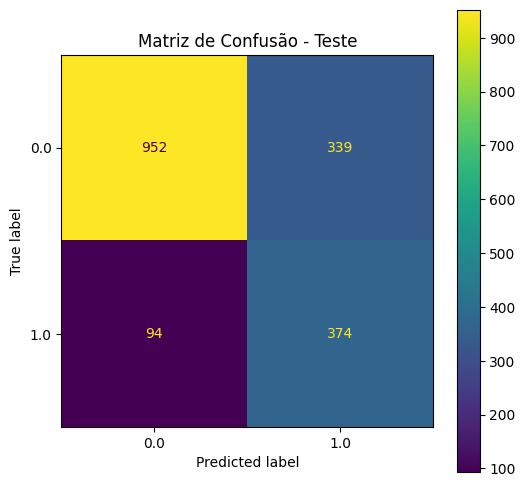

In [ ]:
# === 6. Matriz de Confusão ===
fig, ax = plt.subplots(figsize=(6,6))
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred, ax=ax)
plt.title("Matriz de Confusão - Teste")
plt.show()

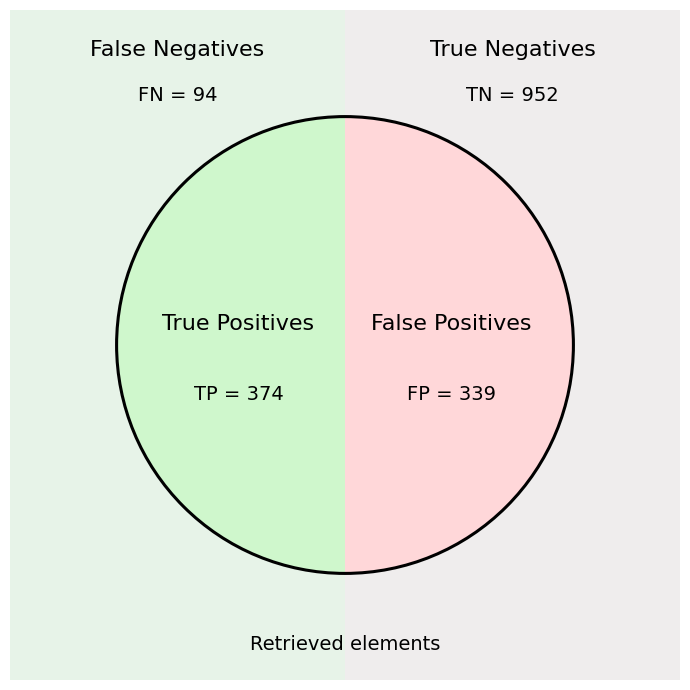

In [ ]:
# === 7. Diagrama TN, FP, FN, TP ===
tn, fp, fn, tp = confusion_matrix(y_test, y_test_pred).ravel()

fig, ax = plt.subplots(figsize=(7,7))
ax.set_aspect('equal')
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.axis('off')

# ==========================================
# 1) FUNDOS (fora do círculo)
# ==========================================

# Esquerda (False Negatives)
bg_left  = Rectangle((-1.1, -1.1), 1.1, 2.2, facecolor='#e7f3e8', edgecolor='none', zorder=0)

# Direita (True Negatives)
bg_right = Rectangle((0.0, -1.1), 1.1, 2.2, facecolor='#efeded', edgecolor='none', zorder=0)

ax.add_patch(bg_left)
ax.add_patch(bg_right)

# ==========================================
# 2) METADE INTERNA DO CÍRCULO (TP e FP)
# ==========================================

radius = 0.75
center = (0, 0)

# TP = metade esquerda interna
tp_wedge = Wedge(center, radius, 90, 270, facecolor='#cff7cc', edgecolor='none', zorder=1)
# FP = metade direita interna
fp_wedge = Wedge(center, radius, 270, 90, facecolor='#ffd7d9', edgecolor='none', zorder=1)

ax.add_patch(tp_wedge)
ax.add_patch(fp_wedge)

# Contorno do círculo
ax.add_patch(Circle(center, radius, facecolor='none', edgecolor='black', lw=2.2, zorder=3))

# ==========================================
# 3) TEXTOS
# ==========================================

# ---- Regiões externas ----
# False Negatives (topo esquerdo)
ax.text(-0.55, 0.95, "False Negatives", fontsize=16, ha='center')
ax.text(-0.55, 0.80, f"FN = {fn}", fontsize=14, ha='center')

# True Negatives (topo direito)
ax.text(0.55, 0.95, "True Negatives", fontsize=16, ha='center')
ax.text(0.55, 0.80, f"TN = {tn}", fontsize=14, ha='center')

# ---- Regiões internas ----
ax.text(-0.35, 0.05, "True Positives", fontsize=16, ha='center')
ax.text(-0.35, -0.18, f"TP = {tp}", fontsize=14, ha='center')

ax.text( 0.35, 0.05, "False Positives", fontsize=16, ha='center')
ax.text( 0.35, -0.18, f"FP = {fp}", fontsize=14, ha='center')

# Texto inferior
ax.text(0, -1.0, "Retrieved elements", fontsize=14, ha='center')

plt.tight_layout()
plt.show()

KS Statistic: 0.5443334611332931
Best threshold: 0.4198134


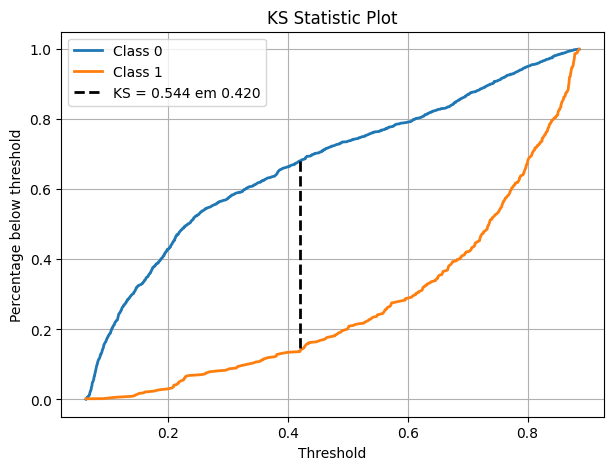

(np.float64(0.5443334611332931), np.float32(0.4198134))

In [ ]:
# === 8. Teste Kolmogorov-Smirnov (KS) ===
calcula_ks(y_test, y_test_proba, True)

In [ ]:
# === 9. AUROC ===
auc = roc_auc_score(y_test, y_test_proba)
print("AUC (Área sob a ROC):", auc)

AUC (Área sob a ROC): 0.842054956404298


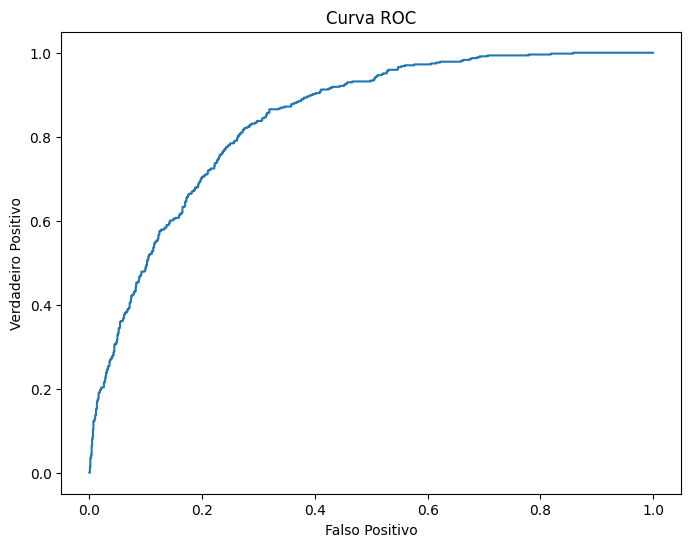

In [ ]:
# === 9.5. Curva ROC ===
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr)
plt.title("Curva ROC")
plt.xlabel("Falso Positivo")
plt.ylabel("Verdadeiro Positivo")
plt.show()

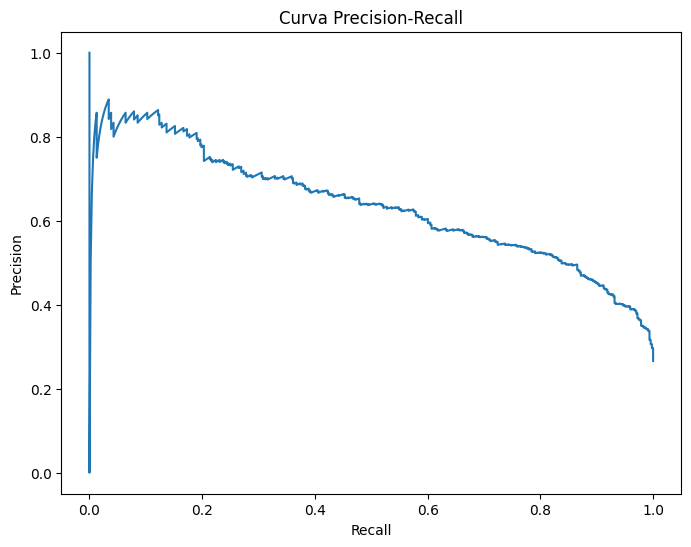

In [ ]:
# === 10. Curva Precision-Recall ===
prec, rec, thr = precision_recall_curve(y_test, y_test_proba)
plt.figure(figsize=(8,6))
plt.plot(rec, prec)
plt.title("Curva Precision-Recall")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()

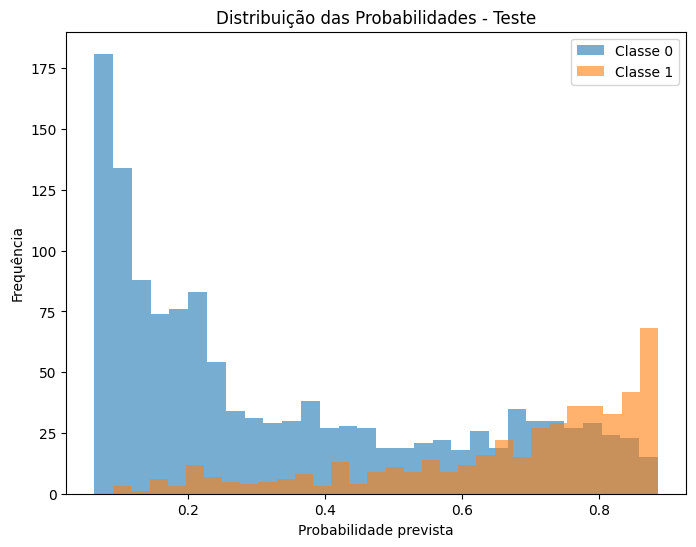

In [ ]:
# === 11. Distribuição das probabilidades ===
plt.figure(figsize=(8,6))
plt.hist(y_test_proba[y_test==0], bins=30, alpha=0.6, label='Classe 0')
plt.hist(y_test_proba[y_test==1], bins=30, alpha=0.6, label='Classe 1')
plt.title("Distribuição das Probabilidades - Teste")
plt.xlabel("Probabilidade prevista")
plt.ylabel("Frequência")
plt.legend()
plt.show()